In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q matplotlib pytest numpy
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    os.chdir(repo_root)
    print("💻 ローカル開発環境を検出しました。作業ディレクトリ:", os.getcwd())


💻 ローカル開発環境を検出しました。作業ディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 9.2 new演算子 (`osbook_day09a`)

本節では、第9章「重ね合わせ処理」の核心コンポーネントである `Window` や `LayerManager`、そして C++ 標準ライブラリコンテナ（`std::vector`）やスマートポインタ（`std::shared_ptr` / `std::make_shared`）を自由自在に生成・運用するために不可欠な**「動的メモリ確保（Dynamic Memory Allocation）」**と**「ヒープ（Heap）領域の解放」**の全貌を徹底解剖します。

---

## 🎯 本節の学習到達目標

1. **なぜ OS カーネルに動的メモリ確保（ヒープ）が必要なのか（動機と限界）**:
   - 第8章で実装した `BitmapMemoryManager` は 4KiB 単位の物理ページフレーム割り当て器（Physical Page Frame Allocator）であり、バイト単位（数バイト〜数百バイト）の細粒度かつ柔軟なメモリ確保には直接使用できません。
   - 9.1 節で設計した `Window`（数万〜数十万バイトのピクセル配列）や `Layer`（数十バイトのメタデータ）、可変個数のレイヤを保持する `std::vector<Layer*>` を静的配列（固定バッファ）で抱える設計は、画面解像度変更やウィンドウ増殖に耐えられず破綻します。
2. **C++ 通常の `new` 演算子と配置 `new` (`placement new`) の本質的相違**:
   - 第4章〜第8章まで多用してきた `new(buffer) Class(...)` は、既存メモリ領域にコンストラクタのみを実行する「配置 new」でした。
   - 通常の `new Class(...)` を呼び出すには、背後で OS からメモリ領域を動的に切り出すヒープアロケータ（`malloc` / `operator new`）の介在が必須となります。
3. **UNIX / POSIX `sbrk()` (set program break) の歴史とメモリモデル**:
   - 伝統的 UNIX から現代まで受け継がれる「プログラムブレーク（Program Break）」の概念と、データセグメント終端アドレスを上下に進退させる `sbrk(intptr_t incr)` の数理。
4. **MikanOS のヒープ初期化アーキテクチャ (`InitializeHeap`)**:
   - `BitmapMemoryManager` から一括で $64 \times 512 = 32{,}768$ フレーム（**128 MiB**）の広大な連続物理領域を確保し、`program_break` を設定する初期化シーケンス。
   - 第8章で完成させた 64GiB 恒等マッピング（Identity Mapping）環境のおかげで、物理フレームのアドレスをそのまま仮想空間のヒープポインタとして透過的に扱える優位性。
5. **5層にわたる動的メモリ割り当てスタックアーキテクチャの完全把握**:
   - `new Window(...)` $\rightarrow$ `operator new` $\rightarrow$ Newlib `malloc` $\rightarrow$ `sbrk` $\rightarrow$ `BitmapMemoryManager` の呼び出し階層と責任分界点の整理。
6. **System V AMD64 ABI に準拠した 16バイトアライメントとチャンク管理**:
   - なぜ 64ビット x86-64 環境ではヒープ割り当てが 16バイトアライメントを遵守しなければならないのか（SSE/AVX 命令のクラッシュ防止）。


---

## 1. 伝統的 UNIX 仮想記憶ヒープ vs MikanOS 恒等マッピング下での 128MiB ヒープ

現代の一般的な Linux 等の UNIX 系 OS では、各プロセスが独立した **48ビット仮想アドレス空間** を持ち、カーネルがページフォルト（Page Fault: `#PF`）例外を介してデマンドページングを行いながらヒープ領域を伸長させます。

しかし、MikanOS の現フェーズ（第9章）では、まだタスクごとの独立したページテーブルや仮想記憶の動的マッピングは導入されていません。第8章で設定した **64GiB 恒等マッピング（Identity Mapping: 仮想アドレス = 物理アドレス）** のフラットな空間上でカーネルが動作しています。

### 数理的導出: MikanOS ヒープ領域の算出

MikanOS の `InitializeHeap()`（`kernel/memory_manager.cpp`）では、起動時に次のようにヒープ領域を確保します：

$$ kHeapFrames = 64 \times 512 = 32{,}768 \text{ フレーム} $$

$$ \text{Total Heap Bytes} = 32{,}768 \times 4{,}096 \text{ B} = 134{,}217{,}728 \text{ B} = 128 \text{ MiB} $$

この 128 MiB の領域は、第8章で実装した `BitmapMemoryManager::Allocate(kHeapFrames)` により、物理メモリの空き領域から連続したフレーム群として一括で確保されます。そして、その先頭アドレスと終端アドレスがグローバル変数に格納されます：

$$ \text{program\_break} = \text{heap\_start} = \text{FrameID} \times 4{,}096 $$
$$ \text{program\_break\_end} = \text{program\_break} + 128 \text{ MiB} $$

以下の対比図（Figure 9.04）は、伝統的な UNIX 仮想アドレス空間のヒープモデルと、MikanOS が採用した 64GiB 恒等マッピング空間における 128MiB ヒープ配置の決定的な構造差を視覚化したものです。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33671: UserWarning: Glyph 12503 (\N{KATAKANA LETTER PU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33671: UserWarning: Glyph 12525 (\N{KATAKANA LETTER RO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33671: UserWarning: Glyph 12475 (\N{KATAKANA LETTER SE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33671: UserWarning: Glyph 12473 (\N{KATAKANA LETTER SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33671: UserWarning: Glyph 29420 (\N{CJK UNIFIED IDEOGRAPH-72EC}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Document

✅ Figure 9.04 生成・保存完了: 9/result/fig9_04_traditional_unix_heap_vs_mikanos_heap.png


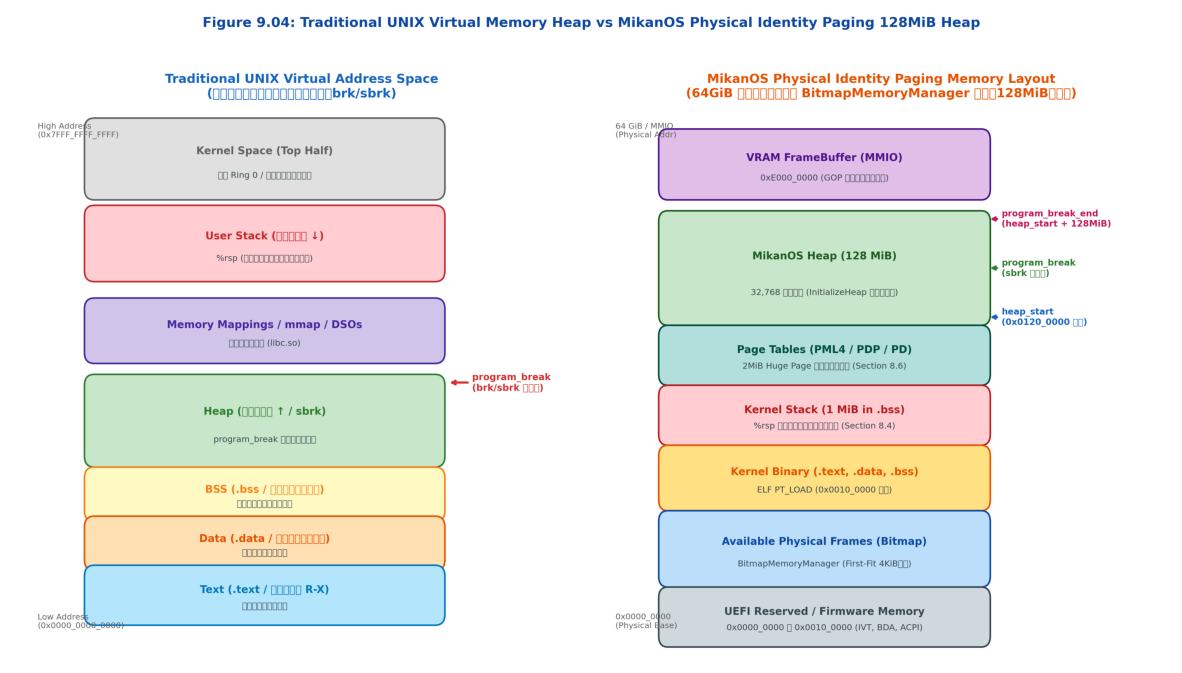

In [2]:
from common import plot_fig9_04_traditional_unix_heap_vs_mikanos_heap
import matplotlib.pyplot as plt
from PIL import Image

fig9_04_path = plot_fig9_04_traditional_unix_heap_vs_mikanos_heap("9/result/fig9_04_traditional_unix_heap_vs_mikanos_heap.png")
print(f"✅ Figure 9.04 生成・保存完了: {fig9_04_path}")

img = Image.open(fig9_04_path)
plt.figure(figsize=(15, 8.5))
plt.imshow(img)
plt.axis("off")
plt.show()


---

## 2. 5層にわたる動的メモリ割り当てスタックアーキテクチャ

私たちが C++ で `auto win = std::make_shared<Window>(width, height);` や `layer_manager = new LayerManager;` と書いたとき、その背後ではどのようなレイヤを通過して物理メモリに到達しているのでしょうか？

MikanOS では、ハードウェア直結の物理メモリからアプリケーションコードに至るまで、**5つの明確な責務階層（Tier 1〜5）** が連携して動的メモリ割り当てを実現しています。

| レイヤ (Tier) | 主要モジュール / 関数 | 主な責務・動作 | メモリ管理単位 |
|:---|:---|:---|:---|
| **Tier 1: C++ アプリ・カーネル** | `new Window(w, h)`, `std::vector<Layer*>` | 型安全なオブジェクト生成、コンストラクタ実行、RAIIによるリソース寿命管理 | オブジェクト単位 |
| **Tier 2: C++ ランタイム** | `void* ::operator new(size_t size)` | 必要バイト数のメモリ確保を標準Cライブラリ `malloc(size)` に要求 | バイト単位 |
| **Tier 3: 標準Cライブラリ (Newlib)** | `malloc(size)`, `free(ptr)` | チャンク管理（ヘッダ＋パディング）、16Bアライメント保証、フリーリスト管理、隣接空き合体 | チャンク単位 (16B〜数KiB) |
| **Tier 4: OS システムコールスタブ** | `caddr_t sbrk(int incr)` (`newlib_support.c`) | プログラムブレーク境界チェック (`program_break + incr < program_break_end`)、ブレーク進退 | 粗いブロック単位 (64KiB等) |
| **Tier 5: 物理フレーム管理** | `BitmapMemoryManager` (`memory_manager.cpp`) | 4KiB ページフレーム単位のビットマップ管理、起動時に 128MiB (32,768フレーム) 一括確保 | 4KiB ページフレーム単位 |

### 配置 new (`placement new`) と通常 `new` の決定的な違い

第4章〜第8章までの MikanOS では、グローバルバッファを用意して配置 new を使用していました：

```cpp
// 第8章までの配置 new (placement new): メモリ確保は行わずコンストラクタのみ実行
char memory_manager_buf[sizeof(BitmapMemoryManager)];
BitmapMemoryManager* memory_manager = new(memory_manager_buf) BitmapMemoryManager;
```

この方式は、起動直後の「ヒープアロケータがまだ存在しない段階」では極めて強力ですが、以下の致命的限界があります：
1. **コンパイル時にバッファサイズが固定される**: 実行時にウィンドウのサイズや個数が可変となる GUI システムに対応できない。
2. **C++ 標準コンテナ（`std::vector`, `std::map`, `std::string` 等）が使えない**: これらのコンテナは内部で通常の `new` / アロケータを呼び出すため、ヒープがなければ動作しない。

通常の `new` が解禁されることで、以下のような極めて直感的かつモダンな C++ コードがカーネル内でそのまま動作するようになります：

```cpp
// 通常の new: ヒープからメモリを確保し、コンストラクタを実行
layer_manager = new LayerManager;
auto mouse_window = std::make_shared<Window>(kMouseCursorWidth, kMouseCursorHeight);
```

以下の図版（Figure 9.05）は、Tier 1 から Tier 5 に至る多層動的メモリスタックのデータフローと責任分界点を詳細に図解したものです。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33730: UserWarning: Glyph 12539 (\N{KATAKANA MIDDLE DOT}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33730: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33730: UserWarning: Glyph 23433 (\N{CJK UNIFIED IDEOGRAPH-5B89}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33730: UserWarning: Glyph 20840 (\N{CJK UNIFIED IDEOGRAPH-5168}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33730: UserWarning: Glyph 12394 (\N{HIRAGANA LETTER NA}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(re

✅ Figure 9.05 生成・保存完了: 9/result/fig9_05_dynamic_allocation_pipeline_new_to_sbrk.png


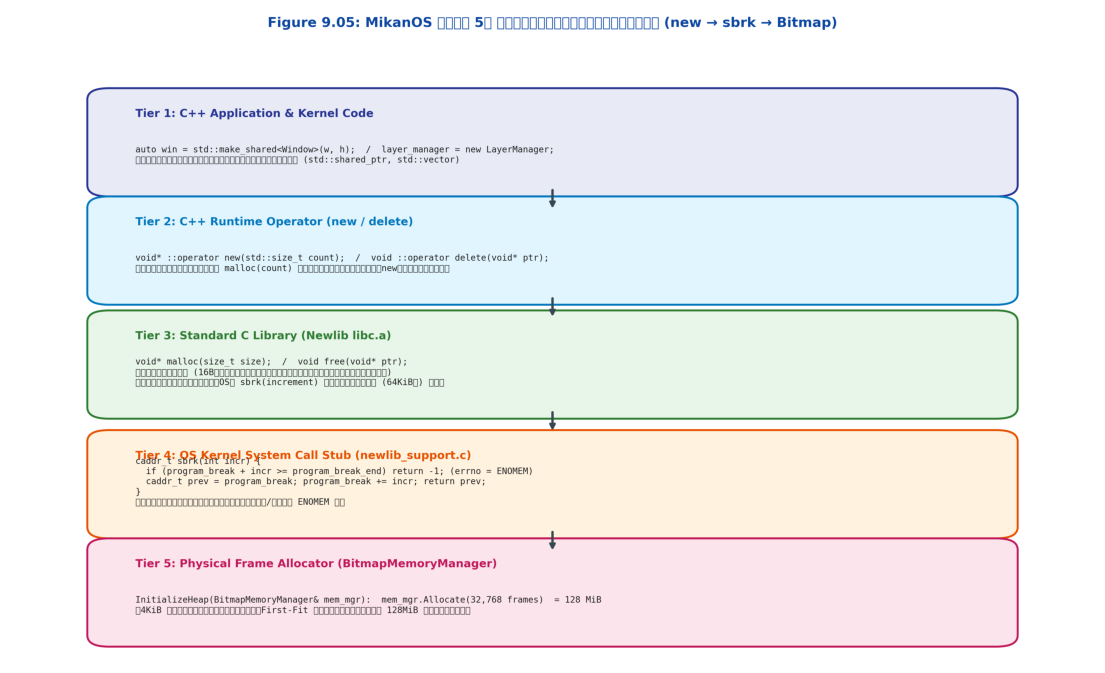

In [3]:
from common import plot_fig9_05_dynamic_allocation_pipeline_new_to_sbrk
import matplotlib.pyplot as plt
from PIL import Image

fig9_05_path = plot_fig9_05_dynamic_allocation_pipeline_new_to_sbrk("9/result/fig9_05_dynamic_allocation_pipeline_new_to_sbrk.png")
print(f"✅ Figure 9.05 生成・保存完了: {fig9_05_path}")

img = Image.open(fig9_05_path)
plt.figure(figsize=(14, 8.5))
plt.imshow(img)
plt.axis("off")
plt.show()


---

## 3. `sbrk()` によるプログラムブレークの進退・チャンク管理・断片化

Newlib 標準Cライブラリの `malloc()` は、OS のシステムコールスタブ `sbrk(int incr)` を呼び出すことでメモリ領域を拡張します。

### MikanOS の `sbrk()` 実装 (`kernel/newlib_support.c`)

```c
caddr_t program_break, program_break_end;

caddr_t sbrk(int incr) {
  if (program_break == 0 || program_break + incr >= program_break_end) {
    errno = ENOMEM;
    return (caddr_t)-1;
  }

  caddr_t prev_break = program_break;
  program_break += incr;
  return prev_break;
}
```

### この実装のポイントと数理規則:
1. **`incr == 0` (ブレーク位置の問い合わせ)**: `program_break` を進めずに現在のアドレスを取得可能。
2. **`incr > 0` (ヒープ領域の拡張)**: 拡張前のブレーク位置 `prev_break` を呼び出し元（`malloc`）に返し、`program_break += incr` でブレークを進める。
3. **境界保護と `ENOMEM`**: `program_break + incr >= program_break_end` を超える要求に対しては、`errno = ENOMEM`（12: Out of Memory）を設定して `(caddr_t)-1` を返し、OS カーネルの他領域への侵食を厳格に阻止する。

### なぜ `sbrk()` 単体では不十分で、`malloc()` のチャンク管理が必須なのか？

`sbrk()` の最大の弱点は、**「プログラムブレークを末尾から一方向に進退させることしかできない」** 点にあります。
もし `sbrk()` だけでメモリ管理を行おうとすると、最初に確保した領域 A を解放（free）したとしても、その後に確保された領域 B や C が生きている限り、プログラムブレークを巻き戻すことはできません。

Newlib の `malloc` は、`sbrk` からある程度まとまった領域（例: 64KiB）を大枠で要求し、その内部を **16バイトアライメントされたチャンク（Chunk）** に細分化して管理します：
- **チャンクヘッダ**: チャンク全体のサイズ、使用中フラグ（In-use flag）
- **フリーリスト（Free List）**: 解放された空きチャンクを双方向・単方向リストで連結
- **隣接ブロック合体（Coalescing）**: 隣り合う空きチャンク同士を1つの大きなチャンクへと自動合体させ、**外部断片化（External Fragmentation）** を解消

以下の図版（Figure 9.06）は、初期状態からオブジェクト確保・解放・合体に至るヒープ状態の推移シーケンスを示しています。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33797: UserWarning: Glyph 21021 (\N{CJK UNIFIED IDEOGRAPH-521D}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33797: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33797: UserWarning: Glyph 29366 (\N{CJK UNIFIED IDEOGRAPH-72B6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33797: UserWarning: Glyph 24907 (\N{CJK UNIFIED IDEOGRAPH-614B}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:33797: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGRAPH-76F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 

✅ Figure 9.06 生成・保存完了: 9/result/fig9_06_sbrk_program_break_transition_and_fragmentation.png


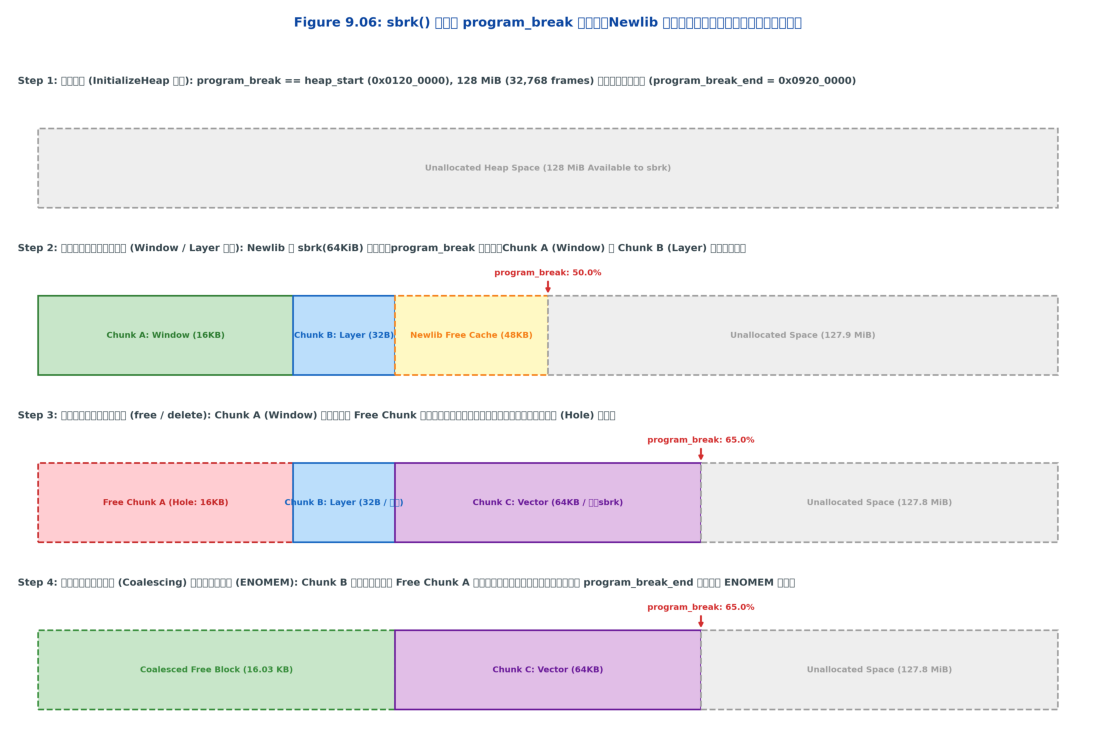

In [4]:
from common import plot_fig9_06_sbrk_program_break_transition_and_fragmentation
import matplotlib.pyplot as plt
from PIL import Image

fig9_06_path = plot_fig9_06_sbrk_program_break_transition_and_fragmentation("9/result/fig9_06_sbrk_program_break_transition_and_fragmentation.png")
print(f"✅ Figure 9.06 生成・保存完了: {fig9_06_path}")

img = Image.open(fig9_06_path)
plt.figure(figsize=(14, 9.5))
plt.imshow(img)
plt.axis("off")
plt.show()


---

## 4. Python による対話的ヒープシミュレータ実験 (`SbrkHeapSimulator`)

本リポジトリの共通モジュール `common.os_sim` に実装された `SbrkHeapSimulator` を用いて、MikanOS のヒープ初期化、`sbrk()` の挙動、16バイトアライメント、解放後の合体（Coalescing）、およびヒープ上限超過時の `ENOMEM` 検知を対話的に実験してみましょう。


In [5]:
from common import SbrkHeapSimulator, MikanBitmapMemoryManagerSim

# 1. 物理ビットマップメモリマネージャから 128 MiB (32,768フレーム) のヒープを初期化
mem_mgr = MikanBitmapMemoryManagerSim(frame_count=65536)
sim = SbrkHeapSimulator(memory_manager=mem_mgr, heap_frames=32768)
init_info = sim.initialize_heap()

print("=== [1] MikanOS ヒープ初期化パラメータ ===")
for k, v in init_info.items():
    hex_str = f" ({hex(v)})" if isinstance(v, int) and v > 1024 else ""
    print(f"  {k:15s}: {v}{hex_str}")

# 2. sbrk(0) による現在ブレークの問い合わせ
initial_brk = sim.sbrk(0)
print(f"\n=== [2] sbrk(0) 問い合わせ: {hex(initial_brk)} ===")

# 3. 動的チャンク確保 (16バイトアライメント検証)
print("\n=== [3] malloc_sim によるオブジェクト確保 ===")
p_win = sim.malloc_sim(256)   # 256B: Window オブジェクトメタデータ
p_layer = sim.malloc_sim(48)  # 48B: Layer オブジェクト
p_vec = sim.malloc_sim(120)   # 120B: std::vector<Layer*> バッファ

print(f"  p_win   (256B): 0x{p_win:08X} (mod 16 = {p_win % 16})")
print(f"  p_layer ( 48B): 0x{p_layer:08X} (mod 16 = {p_layer % 16})")
print(f"  p_vec   (120B): 0x{p_vec:08X} (mod 16 = {p_vec % 16})")

stats_before = sim.get_stats()
print(f"  -> アクティブチャンク数: {stats_before['active_allocated_chunks']}")
print(f"  -> ユーザー要求ペイロード総量: {stats_before['user_payload_bytes']} bytes")
print(f"  -> OSからsbrkで引き出した総量: {stats_before['total_allocated_from_os']} bytes")

# 4. 解放と隣接空きチャンクの自動合体 (Coalescing)
print("\n=== [4] free_sim による解放と隣接合体 ===")
sim.free_sim(p_win)
sim.free_sim(p_layer)
print("  p_win と p_layer を解放しました。隣接する2つの空きチャンクが合体します。")

# 合体した領域 (256+48+ヘッダ) に収まる大きな要求を行う
p_reused = sim.malloc_sim(280)
print(f"  280B の新規割り当て: 0x{p_reused:08X}")
print(f"  -> 元の p_win (0x{p_win:08X}) の位置が再利用されたか: {p_reused == p_win}")

# 5. ヒープ上限超過と ENOMEM 境界テスト
print("\n=== [5] ヒープ枯渇 (Out-of-Memory) 境界テスト ===")
huge_req = sim.remaining_bytes + 1
fail_result = sim.sbrk(huge_req)
print(f"  残り {sim.remaining_bytes} バイトに対して {huge_req} バイト要求")
print(f"  -> sbrk 戻り値: {fail_result} (期待値: -1)")
print(f"  -> errno 設定値: {sim.errno} (ENOMEM = {sim.ENOMEM})")


=== [1] MikanOS ヒープ初期化パラメータ ===
  heap_start     : 1048576 (0x100000)
  heap_end       : 135266304 (0x8100000)
  total_bytes    : 134217728 (0x8000000)
  total_mib      : 128
  heap_frames    : 32768 (0x8000)

=== [2] sbrk(0) 問い合わせ: 0x100000 ===

=== [3] malloc_sim によるオブジェクト確保 ===
  p_win   (256B): 0x00100010 (mod 16 = 0)
  p_layer ( 48B): 0x00100120 (mod 16 = 0)
  p_vec   (120B): 0x00100160 (mod 16 = 0)
  -> アクティブチャンク数: 3
  -> ユーザー要求ペイロード総量: 424 bytes
  -> OSからsbrkで引き出した総量: 65536 bytes

=== [4] free_sim による解放と隣接合体 ===
  p_win と p_layer を解放しました。隣接する2つの空きチャンクが合体します。
  280B の新規割り当て: 0x00100010
  -> 元の p_win (0x00100010) の位置が再利用されたか: True

=== [5] ヒープ枯渇 (Out-of-Memory) 境界テスト ===
  残り 134152192 バイトに対して 134152193 バイト要求
  -> sbrk 戻り値: -1 (期待値: -1)
  -> errno 設定値: 12 (ENOMEM = 12)


---

## 5. C++20 コア実装の解剖とホスト環境スタンドアロン検証

本節の C++20 実装（`src/ch09/os_chapter9_heap_sbrk.cpp`）では、ホスト側環境（Linux / Clang / GCC）上で MikanOS の `BitmapMemoryManager`、`InitializeHeap()`、`sbrk()`、および 16バイトアライメントを保証するチャンク管理機構を完全に再現しています。

以下のテストコードを実行し、全7項目の単体テスト（アライメント、合体、境界保護、枯渇処理）がエラーゼロでパスすることを確認します。


In [6]:
import subprocess

bin_path = "build/bin/ch09_heap_sbrk"
if not os.path.exists(bin_path):
    print("🛠️ ch09_heap_sbrk バイナリをビルド中...")
    subprocess.run(["cmake", "--build", "build", "--target", "ch09_heap_sbrk"], check=True)

result = subprocess.run([bin_path, "--test"], capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print("❌ テスト失敗:", result.stderr)
    sys.exit(1)
else:
    print("🎉 C++20 スタンドアロン検証が全件正常終了しました！")


[Chapter 9.2 Test Suite: Dynamic Allocation & sbrk]

[Test 1] InitializeHeap from BitmapMemoryManager... PASSED (Heap: 512 frames = 2097152 bytes)
[Test 2] sbrk(0) queries current program break... PASSED (break: 0x76c2147ff010)
[Test 3] sbrk(4096) advances program break... PASSED (new break: 0x76c214800010)
[Test 4] sbrk exceeding program_break_end triggers ENOMEM... PASSED (errno=ENOMEM correctly set)
[Test 5] Dynamic Malloc produces 16-byte aligned pointers... PASSED (p1: 0x76c2143fe020, p2: 0x76c2143fe050, p3: 0x76c2143fe0e0)
[Test 6] Free & Coalescing of adjacent free chunks... PASSED (Coalesced block successfully reused)
[Test 7] Heap exhaustion in Malloc returns nullptr gracefully... PASSED (huge allocation rejected)

>>> Chapter 9.2: All C++ tests passed successfully! <<<

🎉 C++20 スタンドアロン検証が全件正常終了しました！


---

## 6. 運用上の落とし穴・セキュリティ・次節への展望

本節で動的メモリ確保（`new` / `malloc` / `sbrk`）が解禁されたことにより、MikanOS のグラフィックスおよびカーネル機能は飛躍的な柔軟性を手に入れました。しかし、ベアメタル環境でのヒープ運用には、現代のアプリケーション開発とは異なる特有の落とし穴が存在します。

### 1. ベアメタルにおける例外無効 (`-fno-exceptions`) と `nullptr` チェックの厳格性
- 一般的なデスクトップ C++ では、ヒープ枯渇時に `new` は `std::bad_alloc` 例外をスローします。
- しかし、MikanOS を含む多くの OS カーネルでは、バイナリサイズ肥大化とスタック巻き戻し（Stack Unwinding）のオーバーヘッドを避けるため、コンパイラオプション `-fno-exceptions` で例外を完全に無効化しています。
- したがって、ヒープ枯渇時に `new` が `nullptr` を返した場合、戻り値のヌルチェックを行わずに参照すると、即座に `#PF` (Page Fault) 例外またはトリプルフォールトが発生してマシンがリセットされます。

### 2. スタック領域とヒープ領域の衝突回避
- 第8章 8.4 節で、私たちはカーネルスタックを `.bss` 領域内の 1MiB 配列（`kernel_main_stack`）に配置しました。
- 一方、本節で確保した 128 MiB のヒープは、`BitmapMemoryManager` が物理メモリの空きフレーム（一般的にはカーネル本体よりも高位のアドレス）から一括確保した独立領域です。
- 伝統的な UNIX のように「スタックが下向き、ヒープが上向きに成長して中央で衝突する」危険性が、MikanOS ではメモリマネージャの分離によって物理的に防止されています。

### 3. 割り込みハンドラ内での `malloc` / `new` 呼び出しの禁止（非リエントラント性）
- 第7章で学んだ通り、割り込みハンドラはカーネルの任意の処理の最中に非同期に割り込みます。
- もしメインループが `malloc()` の最中（フリーリストのポインタを繋ぎ替えている瞬間）に割り込みが発生し、割り込みハンドラ内でも `malloc()` を呼んでしまうと、フリーリストのデータ構造が破壊され、修復不可能な無限ループやメモリ破壊（Race Condition）に陥ります。
- したがって、**「割り込みハンドラ内（Top Half）では絶対に動的メモリ確保を行わない」** という原則が徹底されます。

---

### 🚀 次節への展望

動的メモリ確保の基盤が整ったことで、いよいよ次節 **9.3「重ね合わせ処理の原理 (Window, Layer, LayerManager)」** では、今回解禁された `new` とスマートポインタ（`std::shared_ptr` / `std::unique_ptr`）を駆使して、複数のウィンドウ層を重ね合わせ、マウスカーソルの下にあるデスクトップを一切破壊せずに合成描画する本格的な GUI レンダリングパイプラインを構築します！
